# Strong-lensing cosmography of a galaxy cluster: ΛCDM, wCDM and w0waCDM

This notebook models one cluster from `example_data/` and samples the lens
mass model jointly with the cosmology in three flat models, using Hamiltonian
Monte Carlo (NUTS) with exact JAX gradients:

| model | free cosmological parameters |
|---|---|
| ΛCDM | Ω_m |
| wCDM | Ω_m, w |
| w0waCDM | Ω_m, w0, wa |

It is a trimmed version of `cluster_cosmo_hmc.ipynb`, which also has a
gradient-free (AIES) validation of NUTS and a sampler-diagnostics section.

**Choosing a cluster.** Set `CLUSTER` in the next cell to any folder name in
`example_data/`, or set the environment variable `GLAFIC_CLUSTER`. Each folder
holds catalogues in the glafic public-model format:

| file | columns |
|---|---|
| `glafic_<name>_vN_mulimage.txt` | ID (`system.image`), RA, Dec, positional error ["], z_s, z_s error (> 0: photometric, sampled) |
| `glafic_<name>_vN_memgal.txt` | RA, Dec, L/L*, e, PA of the cluster members (the brightest is the BCG) |
| `glafic_<name>_vN_readme.txt` | lens redshift (`# zl = ...`) and, optionally, the published fit (`# chi2 = .. , dof = ..`) |

With `SPEC_ONLY = True` (the default) systems with a photometric redshift are
left out entirely, so every source redshift is fixed. This also changes the
number of constraints, so the χ² no longer compares directly with the published
fit.

Clusters marked in the `exclude` column of
`example_data/venus_clusters_summary.csv` are judged too complex or not
worth modelling. The notebook refuses to run one unless `RUN_EXCLUDED = True`.
`python build_cluster.py` lists which clusters are excluded.
Rows are matched to folders by the table's `glafic_name` column (the folder
name); a new cluster needs a row there to be excluded.

To add a cluster, drop a new folder in `example_data/`. `build_cluster.py`
lists what it finds (`python build_cluster.py`).

**Mass model.** The glafic recipe of Oguri et al. (VENUS, 2026, Sec. 2.3):

* an elliptical NFW halo, with all 6 parameters free;
* pseudo-Jaffe members with σ ∝ L^1/4 and r_trun ∝ L^η, where σ*, r_trun* and
  η are free;
* optional external shear (`shear`, off by default);
* optional multipoles centred on the BCG (`mpoles`) and an optional separate
  BCG (`bcg`).

Every cluster runs with no per-cluster settings. The shear is off by
default because it is often consistent with zero. Its angle is then
unconstrained, and the amplitude–angle pair forms a funnel at γ = 0 that
NUTS samples poorly.

**Automatic model selection** (`AUTO_MODEL`, stage A). The base model is fitted
first and checked with glafic's exact image finder. It fails the check if a
system has fewer predicted than observed images, if an observed image lies more
than `IMG_OFFSET_MAX` σ from every predicted image, or if an observed image has
|μ| > `MU_CRIT` at the best fit (the source-plane χ² rewards putting an image on
a critical curve, where any offset maps to a tiny source-plane residual). If
the base model fails, each multipole in `MODEL_CANDIDATES` (m = 3 and m = 4,
centred on the BCG) is added in turn and refitted. Among the candidates that pass, the one with the lowest BIC is
kept; if none passes, a second component is added to the closest one (at most
`MAX_ADDITIONS`). A cluster that still fails stops with an error and needs a
model by hand. With `BIC_SELECT = True`, a component is also added to a
passing model when it lowers the BIC by more than `BIC_MIN_DROP`. The χ² alone
is not enough: for RXJ2129 the base model's χ² is only 2.7 worse than with an
m = 3 multipole, but it puts image 6.2 on a critical curve and loses two images
of system 6. Setting `mpoles`, `bcg`, `shear` or `halo` for a cluster in
`CLUSTER_MODEL` fixes its model by hand and skips the search.

Only multipoles are candidates. A separate BCG (`bcg=True`), external shear
(`shear=True`) and a generalized NFW halo with a free inner slope
(`halo="gnfw"`) can be set by hand, but they change more than the angular
structure. In tests on RXJ2129, a free BCG was fitted with almost no mass,
and the gNFW's inner slope ran to its lower limit (a flat core). Both lower
the χ² a lot, but they move mass between the halo, the BCG and the members.

**Image parities** (the sign of 1/μ). The source-plane χ² does not check
which side of a critical curve an image lies on. For an image pair merging
across a critical curve, this lets the posterior split into a physical mode,
with the curve between the two images, and an unphysical one. With
`PARITY = "auto"` (the default), stage A finds the best fit without a
parity constraint. Every **close pair** (images of one system closer than
`PAIR_SEP`) that has opposite parities there then has both parities fixed.
Close pairs with the same parity are reported but not constrained: if one of
them is really a merging pair, the best fit is in the wrong mode, and you set
its signs by hand (`parity={"3.3": -1, "3.4": +1}` in `CLUSTER_MODEL`).

The constraint is a steep χ² penalty on the true 1/μ at the observed
positions (`PARITY_TOL`), not glafic's own parity column. In the
source-plane χ², glafic checks the sign of a linearly corrected
magnification, which for |μ| ≳ 100 is dominated by the correction and has an
essentially random sign.

Each candidate's fit is cached in `results/<cluster>/model_search/`, and the
decision in `results/<cluster>/model_choice.json`, which later runs with the
same settings reuse.

### Likelihood

We use glafic's **source-plane χ²** (`chi2_splane 1`), the choice of most
published cluster models:

* Each image's offset is mapped back to the source plane with the
  magnification tensor of the lens model.
* The source positions are **integrated out analytically**:
  χ² → χ²_min + ln det M, which removes two nuisance parameters per system.
* Positional errors are **rescaled** so that the fixed-cosmology best fit has
  χ²/dof = 1.

The μ² weighting in this χ² is what stops a model from placing images on
critical curves, where any image offset maps to a tiny source-plane residual.
Images that really do lie close to critical curves make the likelihood
sharply peaked, so NUTS needs long warmup and a high target acceptance. Do
**not** use `mag_cap`: capping the magnification removes that protection.

### Stages

Everything for a cluster goes in one folder, `results/<cluster>/`: the glafic
input files, the cached result of each stage (re-running skips finished
stages) and every figure as a PNG. The folder holds one model setup at a time.
`setup.json` records its model tag, which changes with the multipoles, the
BCG, the shear, the parities, `SPEC_ONLY` and the halo-mass parameterization.
Running a different setup into the same folder stops with an error instead
of reusing stale results; move or rename the folder to keep both. Each cached
file also records its cluster and model tag.

| stage | what |
|---|---|
| A | best fit at fixed cosmology (Ω_m = 0.3, w = −1); error calibration; parities; image check |
| B | NUTS for each cosmological model in `MODELS` (ΛCDM, wCDM, w0waCDM) |
| C | cosmology corner plot of all models; lens-parameter table; posterior-predictive check |

`MODELS` in the next cell picks which cosmologies to sample, for example one
per batch job; with `MODELS = []` only stage A runs. The samplers write
a checkpoint every `chunk` samples, so a job that hits its time limit resumes
where it stopped.

In [1]:
import os, sys, re, json, time, math, shutil
import numpy as np
import matplotlib.pyplot as plt

HERE = os.path.abspath(".")
REPO = os.path.abspath(os.path.join(HERE, "..", ".."))
try:
    import glafic_jax as gj
except ImportError:                      # not pip-installed: use the repository copy
    sys.path.insert(0, os.path.join(REPO, "python"))
    import glafic_jax as gj
import jax, jax.numpy as jnp
import build_cluster as build

print("jax", jax.__version__, "| backend:", jax.default_backend(), "| devices:", jax.devices())

# ---------------- configuration ----------------
CLUSTER = os.environ.get("GLAFIC_CLUSTER", "rj2129")   # folder name in example_data/
RUN_EXCLUDED = False              # allow a cluster marked in the summary table's 'exclude' column
if build.is_excluded(CLUSTER) and not RUN_EXCLUDED:   # marked in example_data/venus_clusters_summary.csv
    raise ValueError(f"{CLUSTER} is excluded in venus_clusters_summary.csv; set RUN_EXCLUDED = True to run it")
CLUSTER_MODEL = {                 # optional per-cluster settings; "mpoles", "bcg", "shear" or "halo" fix the model by hand
    # "<name>": dict(mpoles=[(3, 2)], bcg=True, shear=True, halo="gnfw", parity={"3.3": -1, "3.4": +1}),
}
MANUAL_MODEL = {k: v for k, v in CLUSTER_MODEL.get(CLUSTER, {}).items() if k in ("mpoles", "bcg", "shear", "halo")}
AUTO_MODEL = True                 # without a manual model: add components when the base model fails the image check
MODEL_CANDIDATES = [dict(mpoles=[(3, 2)]), dict(mpoles=[(4, 2)])]   # multipoles only (see the introduction)
MAX_ADDITIONS = 2                 # at most this many components are added to the base model
BIC_SELECT = False                # also add a component to a passing model if it lowers the BIC by > BIC_MIN_DROP
BIC_MIN_DROP = 10.0
IMG_OFFSET_MAX = 5.0              # image check fails if an observed image is > this many σ from every predicted one
MU_CRIT = 1000.0                  # ... or has |μ| above this at the best fit (it sits on a critical curve)
PARITY = CLUSTER_MODEL.get(CLUSTER, {}).get("parity", "auto")
# "auto": fix the parities of close pairs that straddle a critical curve at the best fit;
# {image ID: ±1}: required signs of 1/μ, set by hand;  {}: no parity constraint
PAIR_SEP = 2.0                    # [arcsec] images of one system closer than this form a close pair
SPEC_ONLY = True                  # use only spectroscopically confirmed systems (drop photometric z_s)
MAG_CAP = 0.0                     # 0 = glafic's exact source-plane chi2 (do not cap; see above)
POS_ERR0 = 0.4                    # catalogue positional error [arcsec], before rescaling
CALIBRATE_ERRORS = True           # rescale errors so that the fixed-cosmology best fit has chi2/dof = 1
N_STARTS = 16                     # jittered L-BFGS starts for the MAP
USE_NFW_ALPHA = True              # halo mass: sample log10 of the NFW deflection at R (straightens M-c)
NFW_ALPHA_R = None                # [arcsec]; None = median image distance from the BCG
NFW_ALPHA_ZS = None               # source z for the deflection; None = median z_s
COSMO_REPARAM = {"wa": ("sum_below", "weos", -3.0, 2.0, 0.0)}   # DESI: wa in [-3, 2], w0 + wa < 0
W_PRIOR = "desi"                  # tag of the w0/wa prior in the chain file names (w0 in [-3, 1]: prior file)
NUTS_KW = dict(num_chains=4, num_warmup=1000, num_samples=1000, target_accept=0.95,
               max_tree_depth=10, init="map", init_jitter=0.01, use_approx_mass=False, chunk=250)
MODELS = ["lcdm", "wcdm", "w0wa"]   # cosmologies to sample in stage B (finished ones are loaded from disk)
SMOKE_TEST = False                # tiny runs, to check that the notebook works end to end

RESULTS = os.path.join(HERE, "results_smoke" if SMOKE_TEST else "results", CLUSTER)
if SMOKE_TEST:
    NUTS_KW.update(num_chains=2, num_warmup=20, num_samples=20, chunk=10, max_tree_depth=5)

jax 0.12.0.1 | backend: gpu | devices: [CudaDevice(id=0), CudaDevice(id=1), CudaDevice(id=2), CudaDevice(id=3)]


## 1. Data

as1063: z_l = 0.348; 77 images of 27 systems, 0.73 < z_s < 6.11 (0 photometric); 316 members; images at 3.6-50.2" from the BCG; left out (no spectroscopic z): systems 3, 8, 9, 15, 18, 19, 20, 21, 22, 23, 24, 25, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 41, 42, 45, 47, 48, 49, 50, 51, 53, 61, 62; published fit chi2 = 205.60 for 193 dof


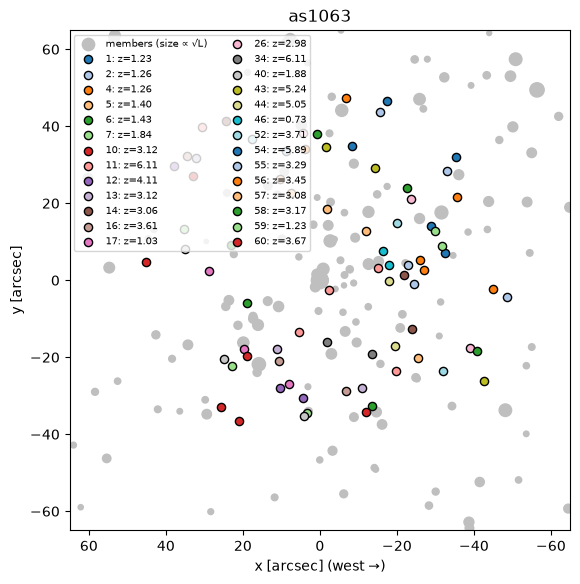

In [2]:
cl = build.load(CLUSTER, spec_only=SPEC_ONLY)
print(build.summary(cl))
if PARITY != "auto":
    bad = set(PARITY) - {iid for s in cl["systems"].values() for iid in s["ids"]}
    if bad:
        raise ValueError(f"PARITY refers to images not in the fit (photometric systems with SPEC_ONLY?): "
                         f"{sorted(bad)}")
if len({round(s["zs"], 3) for s in cl["systems"].values()}) < 2:
    print("WARNING: all systems are at one source redshift; the lens model can be fitted, "
          "but the cosmology is unconstrained (it needs distance ratios between source planes)")
systems = cl["systems"]
SIDS = list(systems)                                   # catalogue system IDs, in glafic point order
xy_all = np.concatenate([np.array(s["xy"]) for s in systems.values()])
r_img = np.hypot(*xy_all.T)
zs_all = np.array([s["zs"] for s in systems.values()])
LIM = 5.0 * math.ceil(1.25 * r_img.max() / 5.0)        # plot half-width [arcsec]

# halo-mass parameterization (data-driven defaults)
if NFW_ALPHA_R is None:
    NFW_ALPHA_R = float(np.round(2 * np.median(r_img)) / 2)
if NFW_ALPHA_ZS is None:
    NFW_ALPHA_ZS = float(np.round(np.median(zs_all), 2))
def halo_reparam(cfg):
    # sampled parameterization: halo mass as log10 of the NFW deflection at NFW_ALPHA_R (or log10 M),
    # member truncation radius flat in log10
    return {f"lens1_{cfg.get('halo', 'anfw')}_p2": ("nfw_alpha", NFW_ALPHA_R, NFW_ALPHA_ZS) if USE_NFW_ALPHA
            else "log10", "lens2_gals_p7": "log10"}

# results: one folder per cluster, holding one model setup at a time
_PARITY_TAG = ["autopar"] if PARITY == "auto" else ["mupar" + "-".join(sorted(PARITY))] if PARITY else []
_NFW_TAG = [f"nfwa{NFW_ALPHA_R:g}z{NFW_ALPHA_ZS:g}" if USE_NFW_ALPHA else "log10M"]
SETTINGS_TAG = "_".join((["speconly"] if SPEC_ONLY else []) + _PARITY_TAG
                        + ([f"cap{MAG_CAP:g}"] if MAG_CAP else []) + _NFW_TAG)   # everything but the mass model


def model_tag(cfg):
    # name of a model setup: the mass model cfg (mpoles, bcg, shear) plus the settings above
    return "_".join(["base"] + (["speconly"] if SPEC_ONLY else []) + ([] if cfg["shear"] else ["noshear"])
                    + [f"mpole{m}{n}" for m, n in cfg["mpoles"]] + (["bcg"] if cfg["bcg"] else [])
                    + ([cfg["halo"]] if cfg.get("halo", "anfw") != "anfw" else [])
                    + _PARITY_TAG + ([f"cap{MAG_CAP:g}"] if MAG_CAP else []) + _NFW_TAG)


RUN_DIR = RESULTS                 # every file of this cluster: results/<cluster>/
os.makedirs(RUN_DIR, exist_ok=True)
SETUP_FILE = os.path.join(RUN_DIR, "setup.json")
_old_setup = json.load(open(SETUP_FILE)) if os.path.exists(SETUP_FILE) else {}
if _old_setup.get("settings", SETTINGS_TAG) != SETTINGS_TAG:   # checked again with the model in stage A
    raise ValueError(f"{RUN_DIR} holds results of model {_old_setup.get('tag')!r}, not of settings "
                     f"{SETTINGS_TAG!r}; move or rename it (e.g. to {RESULTS}_{_old_setup.get('tag')}) first")


def show(name):
    # save the current figure as results/<cluster>/<name>.png, then display it
    plt.savefig(os.path.join(RUN_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()


def write_files(outdir, pos_err, cfg=None):
    # glafic files of mass model cfg (default: the selected MODEL_CFG); parities are not written to the obs
    # file (see add_parity_penalty)
    cfg = cfg or MODEL_CFG
    return build.write_all(CLUSTER, outdir, mpoles=cfg["mpoles"], bcg=cfg["bcg"], shear=cfg["shear"],
                           halo=cfg.get("halo", "anfw"), pos_err=pos_err, spec_only=SPEC_ONLY)


gals = cl["gals"]
cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(gals[:, 0], gals[:, 1], s=150 * gals[:, 2] ** 0.5, c="0.75", label="members (size ∝ √L)")
for k, (sid, s) in enumerate(systems.items()):
    xy = np.array(s["xy"])
    ax.scatter(xy[:, 0], xy[:, 1], s=35, color=cmap(k % 20), edgecolor="k", zorder=3,
               label=f"{sid}: z={s['zs']:.2f}" + (f"±{s['zerr']:.1f}" if s['zerr'] > 0 else ""))
ax.set_xlim(LIM, -LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal")
ax.set_xlabel("x [arcsec] (west →)"); ax.set_ylabel("y [arcsec]"); ax.legend(fontsize=7, ncol=2)
ax.set_title(CLUSTER)
show("images")

In [3]:
def capdir(cap):
    return RUN_DIR                # one folder per cluster (a non-zero MAG_CAP is part of the model tag)


# free cosmological parameters of each model (glafic flags), and its label
COSMO_MODELS = {"fixed": ((), "fixed cosmology"),
                "lcdm": (("ovary",), "ΛCDM"),
                "wcdm": (("ovary", "wvary"), "wCDM"),
                "w0wa": (("ovary", "wvary", "wavary"), "w0waCDM")}


def make_model(cap, cosmo="fixed", lens=None, poi=None, d=None):
    m = gj.read_input(os.path.join(d or capdir(cap), f"{CLUSTER}.input"))
    free = COSMO_MODELS[cosmo][0]
    for k in ("ovary", "wvary", "wavary"):
        m.set_secondary(f"{k} {1 if k in free else 0}")
    m.set_secondary(f"mag_cap {cap}")
    if lens is not None:
        m.lens_params = np.array(lens); m.poi_params = np.array(poi)
    m.model_init()
    return add_parity_penalty(m)


PARITY_TOL = 1e-4                 # softness of the parity wall, in 1/μ
# parities in force: set by hand, or (PARITY = "auto") found from the best fit in stage A
PARITY_FIX = {} if PARITY == "auto" else dict(PARITY)
IMG_IDS = [iid for s in systems.values() for iid in s["ids"]]   # same order as the obs file
CLOSE_PAIRS = [(s["ids"][a], s["ids"][b]) for s in systems.values()
               for a in range(len(s["ids"])) for b in range(a + 1, len(s["ids"]))
               if np.hypot(*np.subtract(s["xy"][a], s["xy"][b])) < PAIR_SEP]


def add_parity_penalty(m):
    # chi2 += sum ( min(0, parity * 1/μ) / PARITY_TOL )^2 at the observed positions of the PARITY_FIX images.
    # Zero on the required side of the critical curve, Δχ² = 100 at 1/μ = 1e-3 on the wrong side; smooth,
    # so the MAP can climb out of the wrong side.  Applies to the MAP (m.chi2) and the samplers (log_prob).
    terms = []
    for k, s in enumerate(systems.values()):           # glafic point k = catalogue system k
        js = [j for j, iid in enumerate(s["ids"]) if iid in PARITY_FIX]
        if js:
            tab = m.obs_point[k]["tab"]
            terms.append((k, jnp.asarray(tab[js, 0]), jnp.asarray(tab[js, 1]),
                          jnp.asarray([float(PARITY_FIX[s["ids"][j]]) for j in js]), int(m.nlp_point[k])))
    if not terms:
        return m
    ls, base = m.lens_system, m.chi2

    def chi2_parity(P):
        c = 0.0
        for k, x, y, sgn, nlp in terms:
            mi = ls.ray_shoot(x, y, P["lens"], P["point"][k, 0], P["cosmo"], nlp=nlp).muinv
            c = c + jnp.sum((jnp.minimum(sgn * mi, 0.0) / PARITY_TOL) ** 2)
        return c

    m.chi2_parity = chi2_parity
    m.chi2 = lambda P=None, **kw: base(P, **kw) + chi2_parity(m.params() if P is None else P)
    return m


def dof_of(m):
    nimg = sum(o["tab"].shape[0] for o in m.obs_point)
    nlens = sum(n.startswith("lens") for n in m.theta_names)
    return 2 * nimg - 2 * m.num_poi - nlens


def muinv_obs(m, P):
    # signed 1/μ at every observed image position, in IMG_IDS order
    return np.concatenate([np.asarray(m.lensmodel(jnp.asarray(o["tab"][:, 0]), jnp.asarray(o["tab"][:, 1]),
                                                  float(P["point"][i, 0]), P).muinv)
                           for i, o in enumerate(m.obs_point)])


def auto_parity(m, P):
    # parities of the close pairs that straddle a critical curve (opposite signs of 1/μ) in model P,
    # and one line of explanation per close pair
    mi = muinv_obs(m, P)
    out, notes = {}, []
    for a, b in CLOSE_PAIRS:
        ia, ib = IMG_IDS.index(a), IMG_IDS.index(b)
        sa, sb = int(np.sign(mi[ia])), int(np.sign(mi[ib]))
        txt = f"   close pair {a}/{b}: 1/μ = {mi[ia]:+.4f} / {mi[ib]:+.4f}"
        if sa * sb < 0:
            out[a], out[b] = sa, sb
            notes.append(txt + "  ->  straddles a critical curve; parities fixed")
        else:
            notes.append(txt + "  ->  same parity, not constrained (if this is a merging pair, the best fit is "
                         "in the wrong mode: set its parity in CLUSTER_MODEL)")
    return out, notes


def image_check(m, P, sigma):
    # glafic's exact image finder on model P.  Per system: the predicted images, the offset of each observed
    # image from the nearest predicted one and |μ| at the observed positions.  'fails' lists what is wrong.
    rows, missing = [], []
    for i in range(m.num_poi):
        obs = m.obs_point[i]["tab"]; pred = m.findimg(i + 1, P=P)
        off = np.array([np.sqrt(((pred[:, :2] - p[:2]) ** 2).sum(1).min()) if len(pred) else np.inf for p in obs])
        mu = np.abs(1 / np.asarray(m.lensmodel(jnp.asarray(obs[:, 0]), jnp.asarray(obs[:, 1]),
                                               float(P["point"][i, 0]), P).muinv))
        rows.append(dict(sid=SIDS[i], zs=float(P["point"][i, 0]), obs=obs, pred=pred, off=off, mu=mu))
        if pred.shape[0] < obs.shape[0]:
            missing.append(SIDS[i])
    off = np.concatenate([r["off"] for r in rows]); mu = np.concatenate([r["mu"] for r in rows])
    jo, jm = int(np.argmax(off)), int(np.argmax(mu))
    fails = []
    if missing:
        fails.append(f"missing images in system(s) {', '.join(map(str, missing))}")
    if off[jo] > IMG_OFFSET_MAX * sigma:
        fails.append(f"image {IMG_IDS[jo]} is {off[jo]:.2f}\" from every predicted image (> {IMG_OFFSET_MAX:g}σ)")
    if mu[jm] > MU_CRIT:
        fails.append(f"image {IMG_IDS[jm]} has |μ| = {mu[jm]:.0f} (on a critical curve)")
    return dict(rows=rows, missing=missing, rms=float(np.sqrt(np.mean(off ** 2))), max_off=float(off[jo] / sigma),
                median_mu=float(np.median(mu)), fails=fails, ok=not fails)


def check_owner(d, path, tag=None):
    # every cached result records the cluster and model it belongs to; refuse to mix them up
    tag = TAG if tag is None else tag
    got = (str(d.get("cluster", CLUSTER)), str(d.get("tag", tag)))
    if got != (CLUSTER, tag):
        raise ValueError(f"{path} belongs to cluster {got[0]!r} / model {got[1]!r}, "
                         f"not {CLUSTER!r} / {tag!r}; move or delete it")
    return d


def save_npz(path, **kw):
    np.savez(path, cluster=CLUSTER, tag=TAG, **kw)


def load_npz(path):
    return check_owner(dict(np.load(path, allow_pickle=True)), path) if os.path.exists(path) else None


# readable parameter names
PLAB = {**{(h, p): lab for h in ("anfw", "gnfw") for p, lab in
           ((2, "M_vir [M_sun/h]"), (3, "x_halo"), (4, "y_halo"), (5, "e_halo"), (6, "θ_halo"), (7, "c_halo"))},
        ("gnfw", 8): "γ_inner (halo)",
        ("gals", 2): "σ* [km/s]", ("gals", 7): "r_trun* [arcsec]", ("gals", 8): "η",
        ("pert", 5): "γ_ext", ("pert", 6): "θ_γ", ("jaffe", 2): "σ_BCG [km/s]", ("jaffe", 7): "r_trun,BCG"}
COSMO_LAB = {"omega": "Ω_m", "weos": "w0", "wa": "wa", "hubble": "h", "lambda": "Ω_Λ"}


def label(n):
    n = str(n)
    m = re.fullmatch(r"lens(\d+)_([a-z0-9]+)_p(\d+)", n)
    if m:
        i, mod, p = int(m.group(1)), m.group(2), int(m.group(3))
        if mod == "mpole" and p in (5, 6):
            mm = MPOLES[i - (2 + int(SHEAR) + int(BCG)) - 1][0]     # lenses: halo, gals, [pert], [jaffe], mpoles
            return f"ε_{mm}" if p == 5 else f"θ_{mm}"
        return PLAB.get((mod, p), n)
    m = re.fullmatch(r"point(\d+)_zs", n)
    if m:
        return f"z_s (system {SIDS[int(m.group(1)) - 1]})"
    return COSMO_LAB.get(n, n)

## 2. Stage A: best fit at fixed cosmology and error calibration

1. **Best fit.** Minimise the source-plane χ² over the lens parameters and
   photometric redshifts, with source positions profiled, from `N_STARTS`
   jittered starts.
2. **Error calibration.** All images share one positional error σ, and the
   χ² scales as 1/σ². Setting σ = σ₀ √(χ²/dof) makes χ²/dof = 1 exactly,
   without changing the best fit.
3. **Parities** (`PARITY = "auto"`). The close pairs that straddle a critical
   curve at the best fit get their parities fixed for all later stages. The
   penalty is zero at the best fit, so the fit and the calibration do not
   change. The signs are saved in `calib.json`.
4. **Model selection** (`AUTO_MODEL`; see the introduction). Steps 1–3 run for
   the base model and, if it fails the image check, for each candidate
   component; the selected model's fit becomes the stage-A result.

If the readme gives a published fit, its χ² (at the catalogue errors) is
printed for comparison. The two match only when the model and the number of
free parameters match the paper's.

In [4]:
def fit_setup(d, cfg, tag, n_starts=N_STARTS):
    # stage A for mass model cfg in folder d (cached in d/calib.json): best fit at fixed cosmology,
    # error calibration, parities
    f = os.path.join(d, "calib.json")
    if os.path.exists(f):
        return check_owner(json.load(open(f)), f, tag)
    os.makedirs(d, exist_ok=True)
    write_files(d, POS_ERR0, cfg)
    m = make_model(MAG_CAP, d=d)                # with PARITY = "auto", no parity constraint yet
    m.set_source_mode("profile")
    dof = dof_of(m)
    if dof <= 0:
        raise ValueError(f"{CLUSTER}: {dof} degrees of freedom ({sum(len(s['xy']) for s in systems.values())} "
                         f"images in {len(systems)} systems): too few constraints for this model")
    pipe = gj.Pipeline(m, reparam=halo_reparam(cfg))
    for k, (ns, jit) in enumerate([(n_starts, 0.5), (4 * n_starts, 1.0), (8 * n_starts, 1.5)]):
        try:
            r = pipe.map(n_starts=ns, jitter=jit, seed=k, verbose=False)
            break
        except ValueError as err:
            print(f"MAP attempt {k + 1}: {err}; retrying with more, wider starts")
    else:
        raise RuntimeError("MAP failed from every start")
    P = m.best_sources(m.unflatten(jnp.asarray(r["theta"])))
    # parities: read off the best fit (zero penalty there) or set by hand
    parity, notes = auto_parity(m, P) if PARITY == "auto" else (dict(PARITY), [])
    sig = POS_ERR0 * np.sqrt(r["chi2"] / dof) if CALIBRATE_ERRORS else POS_ERR0
    write_files(d, sig, cfg)
    nobs = 2 * sum(o["tab"].shape[0] for o in m.obs_point)
    npar = sum(n.startswith("lens") or n.endswith("_zs") for n in m.theta_names)
    out = dict(cluster=CLUSTER, tag=tag, model=cfg, cap=MAG_CAP, sigma=float(sig), chi2_raw=float(r["chi2"]),
               dof=int(dof), nobs=int(nobs), npar=int(npar), lens=np.asarray(P["lens"]).tolist(),
               poi=np.asarray(P["point"]).tolist(), parity=parity, parity_notes=notes)
    json.dump(out, open(f, "w"))
    return out


def merged(cfg, add):
    # mass model cfg with the components of add
    out = dict(mpoles=[tuple(p) for p in cfg.get("mpoles", [])], bcg=bool(cfg.get("bcg", False)),
               shear=bool(cfg.get("shear", False)), halo=add.get("halo", cfg.get("halo", "anfw")))
    out["mpoles"] += [tuple(p) for p in add.get("mpoles", []) if tuple(p) not in out["mpoles"]]
    out["bcg"] |= bool(add.get("bcg", False)); out["shear"] |= bool(add.get("shear", False))
    return out


def evaluate(cfg):
    # fit candidate cfg in results/<cluster>/model_search/<tag>/ (cached) and run the image check
    tag = model_tag(cfg); d = os.path.join(RUN_DIR, "model_search", tag)
    t0 = time.time()
    c = fit_setup(d, cfg, tag)
    m = make_model(MAG_CAP, lens=c["lens"], poi=c["poi"], d=d)
    chk = image_check(m, m.params(), c["sigma"])
    e = dict(cfg=cfg, tag=tag, dir=d, calib=c, ok=chk["ok"], fails=chk["fails"], missing=len(chk["missing"]),
             max_off=chk["max_off"])
    print(f"   {tag:55s} chi2 {c['chi2_raw']:8.2f}  {c['npar']:3d} par  BIC {bic(e):8.2f}  "
          + ("passes" if e["ok"] else "FAILS: " + "; ".join(e["fails"])) + f"  ({time.time() - t0:.0f} s)")
    return e


def bic(e):
    # BIC with the chi2 at a common positional error (the base model's calibrated sigma)
    c = e["calib"]
    return c["chi2_raw"] * (POS_ERR0 / SIGMA_REF) ** 2 + c["npar"] * np.log(c["nobs"])


BASE_MODEL = dict(mpoles=[], bcg=False, shear=False, halo="anfw")
_search_key = dict(settings=SETTINGS_TAG, candidates=[merged(BASE_MODEL, a) for a in MODEL_CANDIDATES],
                   max_additions=MAX_ADDITIONS, bic_select=BIC_SELECT, bic_min_drop=BIC_MIN_DROP,
                   img_offset_max=IMG_OFFSET_MAX, mu_crit=MU_CRIT)
CHOICE_FILE = os.path.join(RUN_DIR, "model_choice.json")
t0 = time.time()
if MANUAL_MODEL or not AUTO_MODEL:
    MODEL_CFG = merged(BASE_MODEL, MANUAL_MODEL)
    print("mass model " + ("set by hand in CLUSTER_MODEL" if MANUAL_MODEL else "= base model (AUTO_MODEL off)"))
elif os.path.exists(CHOICE_FILE) and json.load(open(CHOICE_FILE)).get("key") == json.loads(json.dumps(_search_key)):
    MODEL_CFG = merged(BASE_MODEL, json.load(open(CHOICE_FILE))["model"])
    print(f"mass model: {model_tag(MODEL_CFG)} (selected earlier; see {CHOICE_FILE})")
else:
    print("model selection (image check, then BIC):")
    _base = model_tag(BASE_MODEL)       # its calibrated σ is the common error for the BIC comparison
    SIGMA_REF = fit_setup(os.path.join(RUN_DIR, "model_search", _base), BASE_MODEL, _base)["sigma"]
    cur = evaluate(BASE_MODEL); tried = [cur]
    for _ in range(MAX_ADDITIONS):
        if cur["ok"] and not BIC_SELECT:
            break
        trials = [evaluate(merged(cur["cfg"], a)) for a in MODEL_CANDIDATES if merged(cur["cfg"], a) != cur["cfg"]]
        tried += trials
        passing = [t for t in trials if t["ok"]]
        if not cur["ok"]:            # repair: the best passing candidate, else the closest one gets another component
            cur = min(passing, key=bic) if passing else min(trials, key=lambda t: (t["missing"], t["max_off"]))
        else:                        # BIC_SELECT: keep a component only for a clear BIC gain
            best = min(passing, key=bic, default=None)
            if best is None or bic(best) > bic(cur) - BIC_MIN_DROP:
                break
            cur = best
    table = [dict(tag=t["tag"], ok=t["ok"], fails=t["fails"], chi2=t["calib"]["chi2_raw"], npar=t["calib"]["npar"],
                  bic=bic(t)) for t in tried]
    json.dump(dict(key=_search_key, model=cur["cfg"] if cur["ok"] else None, tag=cur["tag"], ok=cur["ok"],
                   candidates=table), open(CHOICE_FILE, "w"), indent=1)
    if not cur["ok"]:
        raise RuntimeError(f"{CLUSTER}: no model with up to {MAX_ADDITIONS} added components passes the image check "
                           f"(closest: {cur['tag']}: {'; '.join(cur['fails'])}). Set the model by hand in "
                           f"CLUSTER_MODEL, or exclude the cluster.")
    MODEL_CFG = cur["cfg"]
    if cur["dir"] != RUN_DIR and not os.path.exists(os.path.join(RUN_DIR, "calib.json")):
        shutil.copy(os.path.join(cur["dir"], "calib.json"), os.path.join(RUN_DIR, "calib.json"))
    print(f"selected: {cur['tag']}  (model selection {time.time() - t0:.0f} s)")

MPOLES, BCG, SHEAR, HALO = MODEL_CFG["mpoles"], MODEL_CFG["bcg"], MODEL_CFG["shear"], MODEL_CFG["halo"]
REPARAM = halo_reparam(MODEL_CFG)
TAG = model_tag(MODEL_CFG)
if _old_setup.get("tag", TAG) != TAG:      # one model setup per folder: never mix results of different setups
    raise ValueError(f"{RUN_DIR} holds results of model {_old_setup['tag']!r}, not {TAG!r}; move or rename it "
                     f"(e.g. to {RESULTS}_{_old_setup['tag']}) before running this setup")
json.dump(dict(cluster=CLUSTER, tag=TAG, settings=SETTINGS_TAG, model=MODEL_CFG), open(SETUP_FILE, "w"))
print(f"model: {TAG}  ->  {RUN_DIR}")
write_files(RUN_DIR, POS_ERR0)
print(open(os.path.join(RUN_DIR, f"{CLUSTER}.input")).read().split("start_command")[0])

model selection (image check, then BIC):


   base_speconly_noshear_autopar_nfwa32.5z3.12             chi2   202.03    9 par  BIC   136.33  passes  (36 s)
selected: base_speconly_noshear_autopar_nfwa32.5z3.12  (model selection 89 s)
model: base_speconly_noshear_autopar_nfwa32.5z3.12  ->  /global/cfs/cdirs/deepsrch/lensed_sne_search/glafic2/examples_jax/cluster_cosmo/results/as1063


# glafic input for as1063 (generated by build_cluster.py)
omega     0.300000
lambda    0.700000
weos     -1.000000
hubble    0.700000
prefix    as1063
xmin     -110.0
ymin     -110.0
xmax      110.0
ymax      110.0
pix_ext   0.2
pix_poi   1.0
maxlev    6
galfile   as1063_galfile.dat
chi2_splane    1
chi2_checknimg 0
flatfix   1
ovary     1
wvary     1
wavary    1
hvary     0

startup 2 0 27
lens anfw 0.348 8.0e14  0.0  0.0  0.4  -20.0  6.0  0.0
lens gals  0.348 200.0   0.0  0.0  0.0    0.0 20.0  1.0
point 1.2280 -23.2611 18.6984
point 1.2590 -12.8030 12.1226
point 1.2580 -16.3294 14.1004
point 1.3970 -9.0320 6.3294
point 1.4280 9.4834 -9.8123
point 1.8370 20.5473 -14.5453
point 3.1160 30.6167 -21.5124
point 6.1070 -0.2312 0.6777
point 4.1130 17.5666 -9.7013
point 3.1180 10.8527 -4.8122
point 3.0600 -7.1667 10.0346
point 3.6060 12.7227 -5.7730
point 1.0350 18.9001 -14.1894
point 2.9760 -19.4363 13.9009
point 6.1080 -7.6429 -17.5050
point 1.8750 21.3570 -15.8741
point 5.2370 -19.4914 12.

In [5]:
t0 = time.time()
calib = {MAG_CAP: fit_setup(RUN_DIR, MODEL_CFG, TAG)}   # cached (or copied from the model search)
print(f"stage A: {time.time() - t0:.0f} s")
PARITY_FIX = {k: int(v) for k, v in calib[MAG_CAP]["parity"].items()}   # in force from here on
write_files(capdir(MAG_CAP), calib[MAG_CAP]["sigma"])   # current priors/settings, also for a cached stage A
for ln in calib[MAG_CAP].get("parity_notes", []):
    print(ln)
print(f"parity constraints{' (automatic)' if PARITY == 'auto' else ''}: "
      + (", ".join(f"{k}: {v:+d}" for k, v in PARITY_FIX.items()) or "none"))
for cap, c in calib.items():
    m = make_model(cap, lens=c["lens"], poi=c["poi"]); m.set_source_mode("profile")
    c2 = float(m.chi2(m.params()))
    print(f"cap {cap:g}: chi2 = {c['chi2_raw']:.2f} with σ = {POS_ERR0}\"  ->  σ = {c['sigma']:.3f}\", "
          f"chi2 = {c2:.2f} for {c['dof']} dof")
    if PARITY_FIX:
        print(f"   parity penalty at the MAP: {float(m.chi2_parity(m.params())):.3g} (should be 0)")
ref = cl["ref"]
if "chi2" in ref:
    print(f"published fit ({ref.get('model_ref', 'readme')}): chi2 = {ref['chi2']:.2f} for {ref['dof']:.0f} dof"
          + (f", rms = {ref['rms']:.2f}\"" if "rms" in ref else ""))

stage A: 0 s
parity constraints (automatic): none


cap 0: chi2 = 202.03 with σ = 0.4"  ->  σ = 0.596", chi2 = 91.00 for 91 dof
published fit (2026arXiv261108630O): chi2 = 205.60 for 193 dof, rms = 0.42"


### Check with glafic's exact image finder

The source-plane χ² does not check which images the model actually forms.
For the best fit, we solve the lens equation with glafic's adaptive-mesh
image finder. We then compare the predicted and observed images, and
overlay the critical curves for the lowest, median and highest
spectroscopic source redshifts.

system    1 (z=1.228): 3 observed / 3 predicted, offsets [0.37 0.33 0.69], |μ| [12.5 16.5  5.4]
system    2 (z=1.259): 3 observed / 3 predicted, offsets [0.63 0.33 0.7 ], |μ| [15.4 19.3  3.2]
system    4 (z=1.258): 3 observed / 3 predicted, offsets [0.17 0.09 0.34], |μ| [27.9 33.2  3.7]
system    5 (z=1.397): 3 observed / 3 predicted, offsets [0.95 0.45 0.56], |μ| [4.7 3.6 3.6]
system    6 (z=1.428): 3 observed / 3 predicted, offsets [0.64 0.49 0.26], |μ| [6.5 6.8 4.1]
system    7 (z=1.837): 3 observed / 3 predicted, offsets [0.9  1.11 0.08], |μ| [ 3.7  5.6 11.6]
system   10 (z=3.116): 3 observed / 3 predicted, offsets [1.26 1.57 1.43], |μ| [45.3 12.1  4.5]
system   11 (z=6.107): 5 observed / 5 predicted, offsets [1.33 1.2  0.74 0.5  0.76], |μ| [5.6 5.1 6.6 2.6 1.7]
system   12 (z=4.113): 3 observed / 3 predicted, offsets [0.85 0.74 0.28], |μ| [25.6 33.7  2.7]
system   13 (z=3.118): 3 observed / 3 predicted, offsets [0.06 0.23 0.44], |μ| [4.5 6.6 2.7]
system   14 (z=3.060): 3 observed 

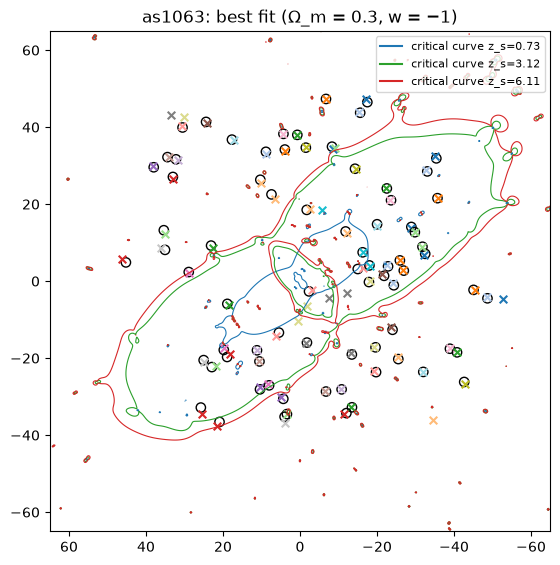

image-plane rms = 0.649 arcsec (expect ~0.60); median |μ| = 6.2; systems with missing images: none


In [6]:
c = calib[MAG_CAP]
m = make_model(MAG_CAP, lens=c["lens"], poi=c["poi"])
P = m.params()
zspec = sorted({s["zs"] for s in systems.values() if s["zerr"] == 0}) or sorted(set(zs_all))
ZCRIT = sorted({zspec[0], zspec[len(zspec) // 2], zspec[-1]})
fig, ax = plt.subplots(figsize=(6.5, 6.5))
g = np.linspace(-LIM, LIM, 501); X, Y = np.meshgrid(g, g)
for zs, col in zip(ZCRIT, ("tab:blue", "tab:green", "tab:red")):
    mu = jax.jit(lambda x, y: m.lensmodel(x, y, zs, P).muinv)(jnp.asarray(X), jnp.asarray(Y))
    ax.contour(X, Y, np.asarray(mu), levels=[0.0], colors=col, linewidths=0.8)
    ax.plot([], [], color=col, label=f"critical curve z_s={zs:.2f}")
chk = image_check(m, P, c["sigma"])
for i, r in enumerate(chk["rows"]):
    print(f"system {str(r['sid']):>4s} (z={r['zs']:.3f}): {r['obs'].shape[0]} observed / {r['pred'].shape[0]} "
          f"predicted, offsets {np.round(r['off'], 2)}, |μ| {np.round(r['mu'], 1)}")
    ax.scatter(r["obs"][:, 0], r["obs"][:, 1], marker="o", facecolor="none", edgecolor="k", s=45)
    ax.scatter(r["pred"][:, 0], r["pred"][:, 1], marker="x", color=cmap(i % 20), s=30)
ax.set_xlim(LIM, -LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title(f"{CLUSTER}: best fit (Ω_m = 0.3, w = −1)")
show("best_fit")
print(f"image-plane rms = {chk['rms']:.3f} arcsec (expect ~{c['sigma']:.2f}); median |μ| = {chk['median_mu']:.1f}; "
      f"systems with missing images: {chk['missing'] or 'none'}")
if not chk["ok"]:
    print("WARNING: the best fit fails the image check (" + "; ".join(chk["fails"]) + "). Do not run the "
          "samplers from it; try more N_STARTS, or another model in CLUSTER_MODEL (multipoles, bcg, shear).")

## 3. Stage B: NUTS for each cosmology

For each model in `MODELS`, NUTS samples the free lens parameters, the
photometric redshifts (if any) and that model's cosmological parameters, with
the source positions marginalised. The priors are flat:

* Ω_m ∈ [0.05, 1] (all models);
* w ∈ [−3, 1] (wCDM); w0 ∈ [−3, 1] and wa ∈ [−3, 2] with **w0 + wa < 0**
  (w0waCDM). These are DESI's ranges. The condition w0 + wa < 0 (no
  dark-energy domination at early times) cuts the (w0, wa) box diagonally;
  wa is sampled as the fraction of its allowed range at the current w0
  (`sum_below`), with the Jacobian included, so the prior is exactly flat in
  (w0, wa) without a wall in the posterior.

Each orientation angle is restricted to one period around the best fit
(`gj.angle_bounds`). Chains start near the stage-A best fit, at Ω_m = 0.3,
w = −1, wa = 0, and the dense mass matrix is adapted during warmup.

Healthy output: few divergences, R-hat < 1.01–1.02, ESS of a few hundred or
more. If the median number of gradient evaluations per sample is
2^max_tree_depth − 1, NUTS is running out of tree depth.

In [7]:
NUTS_FILE = {"lcdm": "nuts_lcdm_om.npz", "wcdm": f"nuts_wcdm_{W_PRIOR}.npz", "w0wa": f"nuts_w0wa_{W_PRIOR}.npz"}
REPARAM_OF = {"lcdm": REPARAM, "wcdm": REPARAM, "w0wa": dict(REPARAM, **COSMO_REPARAM)}


def nuts_stage(path, model, theta0, reparam, **over):
    out = load_npz(path)
    if out is not None:
        return out
    pipe = gj.Pipeline(model, reparam=reparam, bounds=gj.angle_bounds(model, theta0))
    pipe.set_map(theta0)
    h = pipe.hmc(checkpoint=path.replace(".npz", ".ckpt"), **dict(NUTS_KW, **over))
    d = gj.diagnostics(h)
    save_npz(path, theta=h["theta"], log_prob=h["log_prob"], diverging=h["diverging"],
             num_steps=h["num_steps"], names=np.array(h["names"]), rhat=d["rhat"], ess=d["ess"],
             time=h["time"])
    return load_npz(path)


def is_source(n):
    return n.startswith("point") and not n.endswith("zs")


def save_txt(fname, txt):
    # print a text summary and save it as results/<cluster>/<fname>
    print(txt)
    open(os.path.join(RUN_DIR, fname), "w").write(txt + "\n")


def show_diag(res, title, fname):
    # sampler summary (time, divergences, R-hat, ESS, posterior mean and std); also saved to results/<cluster>/<fname>
    names = list(res["names"]); keep = [k for k, n in enumerate(names) if not is_source(n)]
    th = res["theta"].reshape(-1, len(names))
    lines = [f"=== {CLUSTER}: {title}   (model {TAG})",
             f"{float(res['time'])/60:.0f} min; divergences {int(res['diverging'].sum())} / {res['diverging'].size}; "
             f"max R-hat {np.nanmax(res['rhat'][keep]):.3f}; min ESS {np.nanmin(res['ess'][keep]):.0f}; "
             f"median {np.median(res['num_steps']):.0f} gradient evaluations per sample",
             f"{'parameter':22s} {'mean':>11s} {'std':>10s} {'R-hat':>7s} {'ESS':>7s}"]
    for k in keep:
        n = names[k]
        lines.append(f"{label(n):22s} {th[:, k].mean():11.4g} {th[:, k].std():10.3g} "
                     f"{res['rhat'][k]:7.3f} {res['ess'][k]:7.0f}")
    save_txt(fname, "\n".join(lines))


def cosmo_model(cap, cosmo):
    c = calib[cap]
    mm = make_model(cap, cosmo=cosmo, lens=c["lens"], poi=c["poi"])
    mm.set_source_mode("marginalize")
    return mm


nuts = {}                          # cosmology -> finished NUTS result
for cosmo in NUTS_FILE:
    path = os.path.join(capdir(MAG_CAP), NUTS_FILE[cosmo])
    res = load_npz(path)
    if res is None and cosmo in MODELS:
        mm = cosmo_model(MAG_CAP, cosmo)
        print(f"--- {COSMO_MODELS[cosmo][1]}: {mm.ndim} sampled parameters")
        res = nuts_stage(path, mm, mm.theta0(), REPARAM_OF[cosmo])
    if res is not None:
        nuts[cosmo] = res
        show_diag(res, COSMO_MODELS[cosmo][1], NUTS_FILE[cosmo].replace(".npz", ".txt"))
        print()

--- ΛCDM: 10 sampled parameters


[HMC] initialised from map; 4 chain(s), method=vectorized


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:10<?, ?it/s]

warmup:   0%|          | 1/1000 [00:26<7:18:47, 26.35s/it]

warmup:   0%|          | 5/1000 [00:29<1:16:28,  4.61s/it]

... (3,961 outputs left out)

sample:  96%|█████████▌| 240/250 [02:15<00:05,  1.80it/s]

sample: 100%|██████████| 250/250 [02:20<00:00,  1.77it/s]

[checkpoint] 1000/1000 samples


[HMC] 4 x 1000 samples, 0/4000 divergent (1932 s); median 127 leapfrog steps/sample
=== as1063: w0waCDM   (model base_speconly_noshear_autopar_nfwa32.5z3.12)
32 min; divergences 0 / 4000; max R-hat 1.002; min ESS 513; median 127 gradient evaluations per sample
parameter                     mean        std   R-hat     ESS
M_vir [M_sun/h]          2.443e+15   3.66e+14   1.000    3065
x_halo                     -0.2526      0.203   0.999    3326
y_halo                     -0.0232       0.18   1.000    3458
e_halo                      0.4865     0.0133   0.999    3472
θ_halo                      -127.8      0.154   1.000    5528
c_halo                       3.861      0.269   1.002     513
σ* [km/s]                    151.5       8.68   1.001    2604
r_trun* [arcsec]             81.66       13.1   1.001    2446
η                           0.3944      0.131   1.001    1520
Ω_m                         0.2085     0.0557   1.002     978
w0                          -1.948      0.568   1.001    

## 4. Stage C: cosmology

One corner plot for all models. Columns are Ω_m, w0 (w for wCDM) and wa; a
model is drawn only in the panels of its own free parameters, so ΛCDM appears
only in the Ω_m histogram and wCDM is absent from every wa panel. Dashed
curves are the priors (grey when all models share it; in the model's colour
when they differ, as for w0, whose prior in w0waCDM is not flat because of
the w0 + wa < 0 cut). Where a posterior follows its prior, the data do not
constrain that parameter. Shading marks the 68% (darker) and 95%
(lighter) regions. Dotted lines mark (Ω_m, w0, wa) = (0.3, −1, 0).

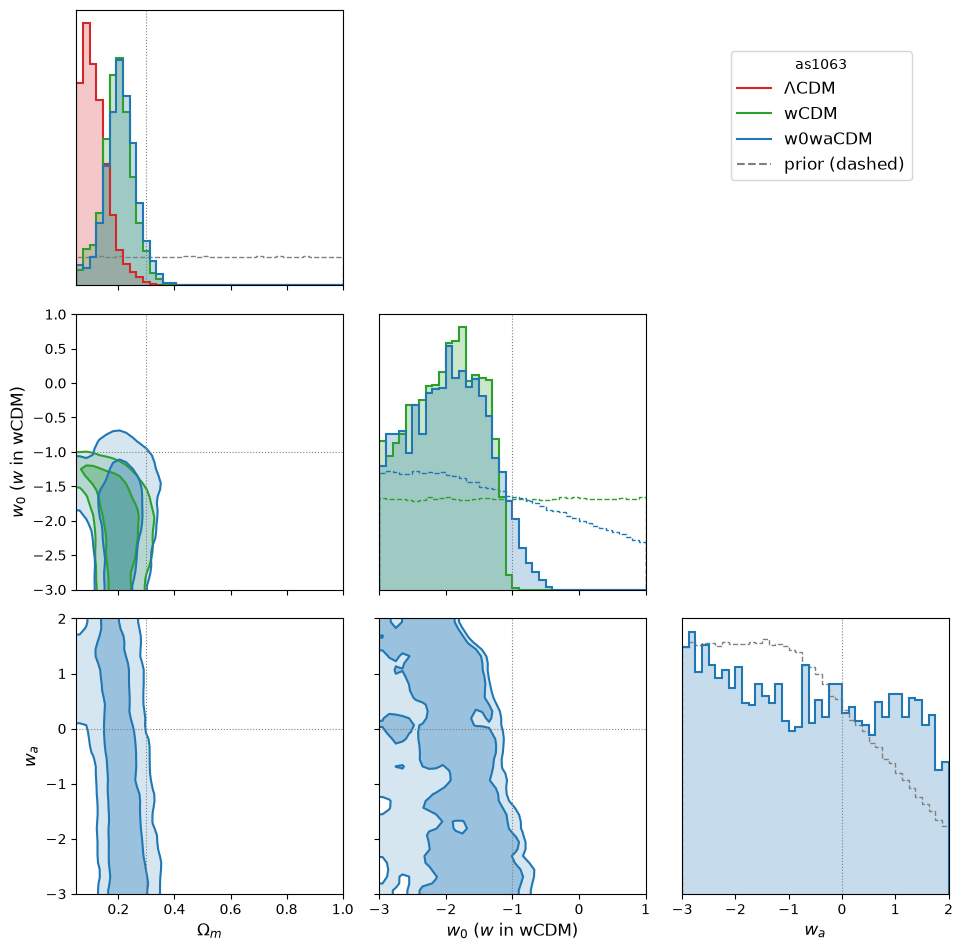

=== as1063: cosmology, median [68%]   (model base_speconly_noshear_autopar_nfwa32.5z3.12)
                                           Ω_m                  w0 (w)                      wa
ΛCDM         posterior     0.11 [ 0.07,  0.16]                                                
             prior         0.52 [ 0.20,  0.85]                                                
wCDM         posterior     0.20 [ 0.15,  0.25]    -1.98 [-2.60, -1.45]                        
             prior         0.52 [ 0.20,  0.85]    -1.00 [-2.36,  0.36]                        
w0waCDM      posterior     0.21 [ 0.16,  0.26]    -1.94 [-2.61, -1.34]    -0.68 [-2.35,  1.07]
             prior         0.52 [ 0.20,  0.85]    -1.41 [-2.50,  0.00]    -1.06 [-2.38,  0.56]

Intervals close to the prior's are prior-dominated, not constraints.


In [8]:
import corner
import matplotlib.colors

COS = [("omega", r"$\Omega_m$", "Ω_m", (0.05, 1.0)),
       ("weos", r"$w_0$ ($w$ in wCDM)", "w0 (w)", (-3.0, 1.0)),
       ("wa", r"$w_a$", "wa", (-3.0, 2.0))]
REF = {"omega": 0.3, "weos": -1.0, "wa": 0.0}
COLORS = {"lcdm": "tab:red", "wcdm": "tab:green", "w0wa": "tab:blue"}


def cosmo_columns(res):
    names = list(res["names"]); th = res["theta"].reshape(-1, len(names))
    return {n: th[:, names.index(n)] for n, *_ in COS if n in names}


def prior_draws(n=400_000, seed=0):
    # {model: {parameter: draws}} from the flat priors actually used: ranges from the prior file and
    # the wa treatment from COSMO_REPARAM.  With the w0 + wa cut, w0's prior in w0waCDM is not flat.
    rng = np.random.default_rng(seed)
    box = {}
    for ln in open(os.path.join(capdir(MAG_CAP), f"{CLUSTER}_prior.dat")):
        t = ln.split()
        if len(t) == 4 and t[0] == "range" and t[1] in ("omega", "weos", "wa"):
            box[t[1]] = (float(t[2]), float(t[3]))
    om = rng.uniform(*box["omega"], n)
    out = {"lcdm": {"omega": om}, "wcdm": {"omega": om, "weos": rng.uniform(*box["weos"], n)}}
    spec = COSMO_REPARAM.get("wa")
    w0 = rng.uniform(*box["weos"], 4 * n)
    keep = np.ones(4 * n, bool)
    if spec and spec[0] == "sum_below":          # flat in (w0, wa) on the box, cut at w0 + wa < cap
        wa = rng.uniform(spec[2], spec[3], 4 * n); keep = w0 + wa < spec[4]
    elif spec and spec[0] == "offset":           # flat in (w0, w0 + wa)
        wa = rng.uniform(spec[2], spec[3], 4 * n) - w0
    else:
        wa = rng.uniform(*box["wa"], 4 * n)
    out["w0wa"] = {"omega": om, "weos": w0[keep][:n], "wa": wa[keep][:n]}
    return out


def shade(color):
    # translucent fills for corner's three bands: outside 95% (clear), the 95% ring, the 68% region
    r, g, b, _ = matplotlib.colors.to_rgba(color)
    return [(r, g, b, 0.0), (r, g, b, 0.18), (r, g, b, 0.45)]


def interval(v):
    q = np.percentile(v, [16, 50, 84])
    return f"{q[1]:6.2f} [{q[0]:5.2f}, {q[2]:5.2f}]"


if nuts:
    cols = {k: cosmo_columns(r) for k, r in nuts.items()}
    prior = prior_draws()
    K = len(COS)
    fig, axs = plt.subplots(K, K, figsize=(3.2 * K, 3.2 * K))
    for i, (ni, li, _, ri) in enumerate(COS):
        for j, (nj, lj, _, rj) in enumerate(COS):
            ax = axs[i, j]
            if j > i:
                ax.axis("off")
                continue
            if i == j:                     # priors: grey if all models share it, else one per model
                pri = {k: prior[k][ni] for k in cols if ni in prior[k]}
                shared = len({id(v) for v in pri.values()}) == 1
                for k, v in pri.items():
                    ax.hist(v, bins=40, range=ri, density=True, histtype="step", ls="--", lw=1,
                            color="0.5" if shared else COLORS[k])
                    if shared:
                        break
            for k, cc in cols.items():
                if i == j and ni in cc:
                    ax.hist(cc[ni], bins=40, range=ri, density=True, histtype="stepfilled", color=COLORS[k],
                            alpha=0.25)
                    ax.hist(cc[ni], bins=40, range=ri, density=True, histtype="step", color=COLORS[k], lw=1.5)
                elif i != j and ni in cc and nj in cc:
                    corner.hist2d(cc[nj], cc[ni], ax=ax, range=[rj, ri], bins=40, smooth=1.0, color=COLORS[k],
                                  levels=(0.68, 0.95), plot_datapoints=False, plot_density=False,
                                  no_fill_contours=True, fill_contours=True,
                                  contourf_kwargs=dict(colors=shade(COLORS[k])))
            ax.axvline(REF[nj], color="0.5", ls=":", lw=0.8)
            ax.set_xlim(rj)
            if i == j:
                ax.set_yticks([])
            else:
                ax.axhline(REF[ni], color="0.5", ls=":", lw=0.8)
                ax.set_ylim(ri)
            if i == K - 1:
                ax.set_xlabel(lj, fontsize=12)
            else:
                ax.set_xticklabels([])
            if j == 0 and i > 0:
                ax.set_ylabel(li, fontsize=12)
            elif i != j:
                ax.set_yticklabels([])
    handles = [plt.Line2D([], [], color=COLORS[k], lw=1.5) for k in cols] + [plt.Line2D([], [], color="0.5", ls="--")]
    fig.legend(handles, [COSMO_MODELS[k][1] for k in cols] + ["prior (dashed)"], loc="upper right",
               bbox_to_anchor=(0.95, 0.95), fontsize=12, title=CLUSTER)
    plt.tight_layout(); show("cosmology_corner")

    lines = [f"=== {CLUSTER}: cosmology, median [68%]   (model {TAG})",
             f"{'':22s}" + "".join(f"{lab:>24s}" for _, _, lab, _ in COS)]
    for k, cc in cols.items():
        lines.append(f"{COSMO_MODELS[k][1]:12s} posterior" + "".join(
            f"{interval(cc[n]) if n in cc else '':>24s}" for n, *_ in COS))
        lines.append(f"{'':12s} prior    " + "".join(
            f"{interval(prior[k][n]) if n in cc else '':>24s}" for n, *_ in COS))
    lines.append("\nIntervals close to the prior's are prior-dominated, not constraints.")
    save_txt("cosmology_summary.txt", "\n".join(lines))

In [9]:
# lens parameters in each cosmology: freeing the cosmology widens the ones degenerate with distances
if nuts:
    base = list(next(iter(nuts.values()))["names"])
    lens_names = [n for n in base if not is_source(n) and n not in ("omega", "weos", "wa")]
    print(f"{'parameter':22s}" + "".join(f"{COSMO_MODELS[k][1]:>26s}" for k in nuts))
    for n in lens_names:
        row = ""
        for res in nuts.values():
            names = list(res["names"]); v = res["theta"].reshape(-1, len(names))[:, names.index(n)]
            row += f"{v.mean():14.4g} ± {v.std():9.3g}"
        print(f"{label(n):22s}{row}")

parameter                                   ΛCDM                      wCDM                   w0waCDM
M_vir [M_sun/h]            1.956e+15 ±  1.55e+14     2.462e+15 ±  3.55e+14     2.443e+15 ±  3.66e+14
x_halo                       -0.3158 ±     0.199       -0.2576 ±     0.205       -0.2526 ±     0.203
y_halo                      -0.05497 ±     0.176       -0.0186 ±      0.18       -0.0232 ±      0.18
e_halo                        0.5125 ±   0.00849        0.4866 ±    0.0133        0.4865 ±    0.0133
θ_halo                        -127.8 ±     0.151        -127.8 ±     0.154        -127.8 ±     0.154
c_halo                         4.895 ±     0.294         3.897 ±     0.281         3.861 ±     0.269
σ* [km/s]                      154.7 ±      8.75         151.4 ±      8.56         151.5 ±      8.68
r_trun* [arcsec]               78.95 ±      14.2         81.62 ±      13.1         81.66 ±      13.1
η                             0.4284 ±      0.13        0.3947 ±     0.128        0.3944 ± 

### Posterior-predictive check with exact image finding

For random posterior draws of the most general model sampled, set the
sources to their best positions and solve the lens equation with glafic's
exact image finder. Count how many draws reproduce every observed image, and
compute the image-plane rms; systems that lose images are listed.

In [10]:
if nuts:
    pp = next(k for k in ("w0wa", "wcdm", "lcdm") if k in nuts)
    mw = cosmo_model(MAG_CAP, pp)            # marginalised sources: matches the sampled theta
    names = list(nuts[pp]["names"]); thw = nuts[pp]["theta"].reshape(-1, len(names))
    rng = np.random.default_rng(1)
    n_ok, rms, lost = 0, [], {}
    nd = 5 if SMOKE_TEST else 20
    for t in thw[rng.choice(len(thw), nd, replace=False)]:
        Pd = mw.best_sources(mw.unflatten(jnp.asarray(t)))
        good, d2 = True, []
        for i in range(mw.num_poi):
            obs = mw.obs_point[i]["tab"]; im = mw.findimg(i + 1, P=Pd)
            if im.shape[0] < obs.shape[0]:
                good = False; lost[SIDS[i]] = lost.get(SIDS[i], 0) + 1
            if len(im):
                d2 += [((im[:, :2] - p[:2]) ** 2).sum(1).min() for p in obs]
        n_ok += good; rms.append(np.sqrt(np.mean(d2)))
    print(f"{COSMO_MODELS[pp][1]}: {n_ok}/{nd} draws form at least the observed number of images in every system; "
          f"image-plane rms = {np.mean(rms):.3f} ± {np.std(rms):.3f} arcsec")
    if lost:
        print("draws losing images, by system:", ", ".join(f"{s}: {c}" for s, c in lost.items()))

w0waCDM: 20/20 draws form at least the observed number of images in every system; image-plane rms = 0.591 ± 0.024 arcsec


## Notes

* **Running several clusters.** One kernel per cluster: set `GLAFIC_CLUSTER`
  in each batch job. Results go to separate folders, and the w0waCDM chain
  (`nuts_w0wa_desi.npz`) is shared with `cluster_cosmo_hmc.ipynb` when the
  model setup is the same.
* **Interpreting the cosmology.** A single cluster constrains ratios of
  distances between source planes, which depend weakly on (Ω_m, w0, wa) and
  are degenerate with the mass model. Compare each posterior with its prior
  in the corner plot; clusters with many spectroscopic systems over a wide
  redshift range constrain it best.
* **Validation.** This notebook has no gradient-free cross-check and no
  sampler-diagnostics section; use `cluster_cosmo_hmc.ipynb` for those.